GXM-01 — Machine Learning Model Development

Objective

Develop and evaluate a binary classification model using the Breast Cancer Wisconsin (Diagnostic) dataset.

This notebook covers:

Data preparation
Feature and target separtion
Stratified train-test splitting
Feature scaling 
Logistic Regression
Model evaluation

The dataset is used for educational and research purposes, not clinical diagnosis.

In [43]:
import pandas as pd 
import numpy as np

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

#Load dataset
dataset = load_breast_cancer()

#Convert features to DataFrame
df = pd.DataFrame(dataset.data,columns=dataset.feature_names)

#Add target
df["target"] = dataset.target

print("Dataset shape:" ,df.shape)


Dataset shape: (569, 31)


In [44]:
# Input features
X = df.drop(columns=["target"])

# Target variable
y = df["target"]

print ("Feature shape:", X.shape)
print ("Target shape:",y.shape)

Feature shape: (569, 30)
Target shape: (569,)


In [45]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)

print("Training samples:", X_train.shape[0])
print("Testing samples:",X_test.shape[0])

Training samples: 455
Testing samples: 114


In [46]:
print("Original distribution:")
print(y.value_counts(normalize=True))

print("\nTraining distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting distribution:")
print(y_test.value_counts(normalize=True))

Original distribution:
target
1    0.627417
0    0.372583
Name: proportion, dtype: float64

Training distribution:
target
1    0.626374
0    0.373626
Name: proportion, dtype: float64

Testing distribution:
target
1    0.631579
0    0.368421
Name: proportion, dtype: float64


Observation - Train-Test Split

the dataset was divided into 80% training data (455 samples) and 20 % testing samples (114 samples).

Stratified sampling was applied to maintain approcimately the same benign-to-malignant class distribution across both subsets

A fixed random state was used to ensure reproducibility. The test dataset will remain separate during model development and will be used for final model evaluation.


Feature Scaling 

StandardScaler is used to standardize numerical features so they have approximately zero mean and unit variance.

The scaler is fitted exclusively on the training dataset to prevent information leakage from the test dataset.

In [47]:
from sklearn.preprocessing import StandardScaler

#intialize scaler

scaler = StandardScaler()

In [48]:
#fit and transform training data

X_train_scaled = scaler.fit_transform(X_train)
print("Scaled training shape:", X_train_scaled.shape)

Scaled training shape: (455, 30)


In [49]:
#Transform test data

X_test_scaled = scaler.transform(X_test)
print("Scaled testing shape:", X_test_scaled.shape)

Scaled testing shape: (114, 30)


In [50]:
print("Mean:", X_train_scaled.mean(axis=0)[:5])
print("Standard deviation:", X_train_scaled.std(axis=0)[:5])

Mean: [-4.31742554e-15  2.24606658e-15 -7.38359313e-16  1.71779562e-16
  5.22695440e-15]
Standard deviation: [1. 1. 1. 1. 1.]


In [51]:
#Build Scikit-lean Pipeline

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression


#Create ML pipeline

model_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

print (model_pipeline)

Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42))])


Observation - Feature Scaling

StandardScaler was applier to standardize the numerical features using statistics calculated exclusively from the training dataset.

The transformed training features have approximately zero mean and unit variance.

A Sckit-lean Pipeline was also defined to combine feature scaling and Logistic Regression into a reproducible workflow. This ensures consistent preprocessing during training and prediction while preventing test-data leakage

Model Training - Logistic Regression 

A Logistic Regression classified is trained using the standardizewd numerical feautures.

The model is implemented through a Scikit-learn Pipeline that combines StandardScaler and LogisitcRegression.

Only the training dataset is used during fitting. the test dataset remains unseen until final evaluation


In [52]:
#Train the model using training data only

model_pipeline.fit(X_train,y_train)
print("Model training completed successfully!")

Model training completed successfully!


In [53]:
# Predict diagnosis for unseen test samples
y_pred = model_pipeline.predict(X_test)

print("First 10 predictions:")
print(y_pred[:10])

print("\nFirst 10 actual labels:")
print(y_test.iloc[:10].values)

First 10 predictions:
[0 1 0 1 0 1 1 0 0 0]

First 10 actual labels:
[0 1 0 1 0 1 1 0 0 0]


In [54]:
#Create a comparison DataFrame
results_df = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted":y_pred
})

#Map numeric labels to diagnosis names
diagnosis_map ={
    0:"Malignant",
    1:"Benign"
}

results_df["Actual"] = results_df["Actual"].map(diagnosis_map)
results_df["Predicted"] = results_df["Predicted"].map(diagnosis_map)

#Display first 10 results
results_df.head(10)


,Actual,Predicted
0,Malignant,Malignant
1,Benign,Benign
2,Malignant,Malignant
3,Benign,Benign
4,Malignant,Malignant
5,Benign,Benign
6,Benign,Benign
7,Malignant,Malignant
8,Malignant,Malignant
9,Malignant,Malignant


In [55]:
# Generate class probabilities
y_prob = model_pipeline.predict_proba(X_test)

print("Class order:", model_pipeline.classes_)
print("\nFist 5 probability predictions:")
print(y_prob[:5])

Class order: [0 1]

Fist 5 probability predictions:
[[9.99999941e-01 5.88824186e-08]
 [1.13351672e-05 9.99988665e-01]
 [9.93589175e-01 6.41082462e-03]
 [4.66491463e-01 5.33508537e-01]
 [9.99999999e-01 6.52500097e-10]]


In [56]:
# Access the trained classifier

classifier = model_pipeline.named_steps["classifier"]


# Extract feature coefficients

coefficients = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": classifier.coef_[0]
})

# Sort by absolute coefficient magnitude
coefficients["Absolute_Coefficient"] =(
    coefficients["Coefficient"].abs()
)

coefficients = coefficients.sort_values(
    by = "Absolute_Coefficient",
    ascending=False
)

coefficients.head(10)

,Feature,Coefficient,Absolute_Coefficient
21,worst texture,-1.255088,1.255088
10,radius error,-1.082965,1.082965
27,worst concave points,-0.953686,0.953686
23,worst area,-0.947756,0.947756
20,worst radius,-0.947616,0.947616
28,worst symmetry,-0.939181,0.939181
13,area error,-0.929104,0.929104
26,worst concavity,-0.823151,0.823151
22,worst perimeter,-0.763220,0.763220
24,worst smoothness,-0.746625,0.746625


Observation - Logistic Regression Model Training

A Logistic Regression classifier was successfully trained using the training dataset through a Scikit-learn Pipeline

The pipeline applies StandardScaler befoer classification, ensuring consistent preprocessing without introducing test-data leakage.

The trained model was used to generate class prediction and probability estimates fore a unseen test dataset.

Learned feature coefficients were also extracted to examine how individual standardized features contribute to the model's predictions

Formal performance evaluation will be performed in the next phase using classification metrics and a confustion matrix

Model Evaluation

This section evaluates the Logistic Regression classifier using the held out test dataset.

Performance is assessed using accuracy,precision,recall,F1_score, a confusion matrix and ROC-AUC.

Special attention is given to false negative, where malignant samples are incorrectly classified as benign

In [57]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve
)

import matplotlib.pyplot as plt

In [58]:
# Generate predicitons using out trained pipeline
y_pred = model_pipeline.predict(X_test)

# Calculate metrics 
accuracy = accuracy_score(y_test,y_pred)

precision = precision_score(y_test,y_pred,pos_label=0)

recall = recall_score(y_test,y_pred,pos_label=0)

f1 = f1_score(y_test, y_pred , pos_label=0)

print(f"Accuracy:{accuracy:.4f}")
print(f"Precision:{precision:.4f}")
print(f"Recall:{recall:.4f}")
print(f"F1-Score:{f1:.4f}")




Accuracy:0.9825
Precision:0.9762
Recall:0.9762
F1-Score:0.9762


In [59]:
# Generate classification report 

print(classification_report(y_test,y_pred,target_names=["Malignant", "Benign"],
                            digits=4))

              precision    recall  f1-score   support

   Malignant     0.9762    0.9762    0.9762        42
      Benign     0.9861    0.9861    0.9861        72

    accuracy                         0.9825       114
   macro avg     0.9812    0.9812    0.9812       114
weighted avg     0.9825    0.9825    0.9825       114



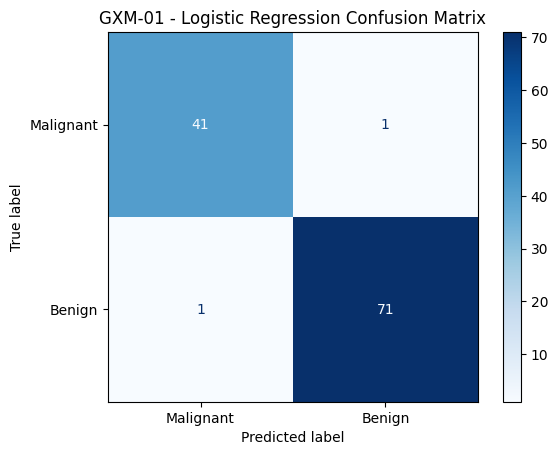

In [60]:
# Generate confusion matrix

cm = confusion_matrix(y_test,y_pred,labels=[0,1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=["Malignant","Benign"])

disp.plot(cmap="Blues",values_format="d")

plt.title("GXM-01 - Logistic Regression Confusion Matrix")
plt.show()

In [61]:
TP,FN = cm[0]
FP,TN = cm[1]

print("True Positives:", TP)
print("False Negatives", FN)
print("False Positives", FP)
print("True Negatives", TN)

True Positives: 41
False Negatives 1
False Positives 1
True Negatives 71


In [69]:
malignant_index = list(model_pipeline.classes_).index(0)

y_prob_malignant = model_pipeline.predict_proba(X_test)[
    :,malignant_index
]

y_test_malignant = (y_test ==0).astype(int)
# Calculate ROC-AUC

# roc_auc = roc_auc_score(y_test,y_prob_malignant,labels=[1,0]) 
# ROC-AUC = 0.0046 //ambiguity! the labels does not change which class Roc-Auc treats as positive 

roc_auc = roc_auc_score(y_test_malignant,y_prob_malignant)

print(f"ROC-AUC:{roc_auc:.4f}")

ROC-AUC:0.9954


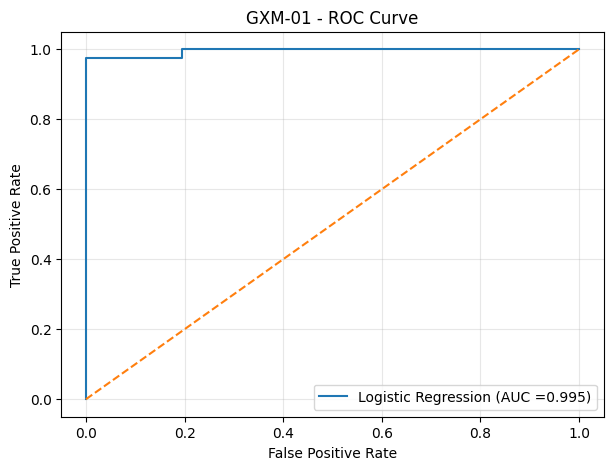

In [70]:
fpr, tpr, thresholds = roc_curve(y_test_malignant,y_prob_malignant)

plt.figure(figsize=(7,5))
plt.plot(fpr,tpr,label =f"Logistic Regression (AUC ={roc_auc:.3f})")

plt.plot([0,1],[0,1],linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("GXM-01 - ROC Curve")
plt.legend()
plt.grid(alpha =0.3)

plt.show()

In [72]:
evaluation_results = pd.DataFrame({
    "Metric" : [
        "Accuracy",
        "Malignant Precision",
        "Malignant Recall",
        "Malignant F1",
        "ROC-AUC",
        "False Negatives"
    ],
    "Value":[
        accuracy,
        precision,
        recall,
        f1,
        roc_auc,
        FN

    ]
})

evaluation_results

,Metric,Value
0,Accuracy,0.982456
1,Malignant Precision,0.976190
2,Malignant Recall,0.976190
3,Malignant F1,0.976190
4,ROC-AUC,0.995370
5,False Negatives,1.000000


Observation - Model Evaluation

The Logistic Regression baseline model was evaluated using 114 previously unseen test samples.

The model achieved :

    Accuracy:	0.982456
	Malignant Precision:	0.976190
	Malignant Recall:	0.976190
	F1-Score:	0.976190
	ROC-AUC:	0.995370

The model correctly classified 112 out of 114 test samples.

The malignant recall of 97.62% indicates that the classifier successfully identified most malignant samples, although one malignant case was incorrectly classified as benign.

The ROC-AUC score of 0.9954 demonstrates strong discrimination between malignant and benign samples in the held-out test dataset.

These results establish the initial Logistic Regression performance baseline for GXM-01.

Further validation, cross-validation and comparison with alternative classification algorithms are required to assess generalization and model stability.

Limitation: This model is developed for educational and research purposes and is not intended for clinical diagnosis.